In [1]:
import pandas as pd
import numpy as np
import pandahouse
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats
import swifter
import hashlib

In [ ]:
# подключаемся к базе данных и выгружаем данные по пользователям 
# (user_id, их эксперементальную группу, лайки, просмотры и ctr) из 1 и 2 группы

connection = {
    'host': 'http://clickhouse.lab.karpov.courses:8123',
    'password': '',
    'user': 'student',
    'database': 'simulator_20261020'
}

q = """
SELECT
    user_id,
    exp_group,
    SUM(action = 'like') AS likes,
    SUM(action = 'view') AS views,
    likes / views AS ctr
FROM 
    {db}.feed_actions
WHERE time::date BETWEEN '2026-10-02' AND '2026-10-08'
    AND exp_group IN (1,2)
GROUP BY 
    exp_group, 
    user_id
"""

df = pandahouse.read_clickhouse(q, connection=connection)

# проверка корректности выгрузки из базы данных
df.groupby('exp_group').count()

,user_id,likes,views,ctr
exp_group,,,,
1,10020,10020,10020,10020
2,9877,9877,9877,9877


In [3]:
# H(0) - средний ctr пользователей в группе с новым алгоритмом рекомендаций (группа 2) статистически не отличается 
# от среднего ctr в контрольной группе (группа 1)

# H(1) - средний ctr пользователей значимо отличается в группах с новым алгоритмом рекомендаций 
# и в контрольной группе

# Контрольная метрика - ctr
# Уровень значимости (alpha) = 0.05

<Axes: xlabel='ctr', ylabel='Count'>

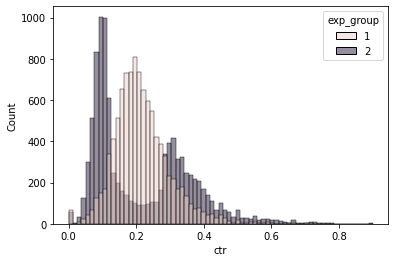

In [4]:
# исследование распределения ctr
sns.histplot(data=df, x='ctr', hue='exp_group')

<Axes: xlabel='exp_group', ylabel='ctr'>

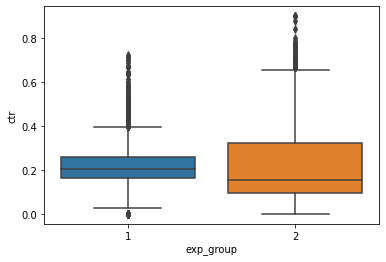

In [5]:
# boxplot
sns.boxplot(data=df, x='exp_group', y='ctr')

In [6]:
# получение описательной статистики
df.groupby('exp_group')['ctr'].describe()

,count,mean,std,min,25%,50%,75%,max
exp_group,,,,,,,,
1,10020.0,0.216774,0.082969,0.0,0.163636,0.205882,0.257870,0.722222
2,9877.0,0.216102,0.142870,0.0,0.096774,0.153285,0.323529,0.900000


In [7]:
# при визуальном анализе распределение ctr у первой группы унимодально, у второй - бимодально, также заметен 
# правый хвост, который говорит о том, что у обеих групп имеются выбросы. медианные значения и график boxplot 
# подтверждает гипотезу о том, что среди обеих (особенно у экспериментальной) групп имеются польззователи с 
# экстремально выоким ctr, распределение значений в целом более размашистое у второй группы, у первой оно более 
# сосредоточенное, группы имеют практически идентичные средние значения ctr.  

In [8]:
# t-test
p_value_ttest = stats.ttest_ind(df[df.exp_group == 2].ctr, 
                                df[df.exp_group == 1].ctr, 
                                equal_var=False, 
                                alternative = 'two-sided').pvalue

print(f'p-value по t-test: {p_value_ttest}')

p-value по t-test: 0.685373331140751


In [9]:
# по результатам t-test Уэлча получено p-value = 0.685, что значительно превышает уровень статистической значимости 0.05, поэтому нет достаточных 
# статистических оснований для того, чтобы отвергнуть нулевую гипотезу

In [10]:
# тест Манна-Уитни
p_value_mannwhitneyu = stats.mannwhitneyu(df[df.exp_group == 2].ctr, 
                                          df[df.exp_group == 1].ctr, 
                                          alternative = 'two-sided').pvalue

print(f'p-value по тесту Манна-Уитни: {p_value_mannwhitneyu}')

p-value по тесту Манна-Уитни: 4.632205841806026e-45


In [11]:
# по результатам теста Манна—Уитни получено p-value, значительно меньшее уровня статистической значимости 0.05. следовательно, нулевая гипотеза об отсутствии 
# различий в распределениях пользовательского CTR отвергается. результат согласуется с визуальным анализом: экспериментальная группа имеет более выраженную 
# неоднородность и больший разброс значений CTR. при этом результаты теста Манна—Уитни не позволяют сделать вывод о том, что средний CTR одной группы выше 
# или ниже другой

In [12]:
# тест Пуассоновский бутстреп
def bootstrap(df, n_bootstrap):
    # лайки 1 и 2 групп
    likes1 = df[df.exp_group == 1].likes.to_numpy()
    likes2 = df[df.exp_group == 2].likes.to_numpy()
    
    # просмотры 1 и 2 групп
    views1 = df[df.exp_group == 1].views.to_numpy()
    views2 = df[df.exp_group == 2].views.to_numpy()
    
    # генерация все Пуассоновских весов
    poisson_bootstraps1 = stats.poisson(1).rvs((n_bootstrap, len(likes1))).astype(np.int64)
    poisson_bootstraps2 = stats.poisson(1).rvs((n_bootstrap, len(likes2))).astype(np.int64)
    
    # расчет CTR для всех итераций бутстрепа
    globalCTR1 = (poisson_bootstraps1*likes1).sum(axis=1)/(poisson_bootstraps1*views1).sum(axis=1)
    globalCTR2 = (poisson_bootstraps2*likes2).sum(axis=1)/(poisson_bootstraps2*views2).sum(axis=1)
    
    return globalCTR1, globalCTR2

ctr1, ctr2 = bootstrap(df, 10000)

print(f'средний глобальный ctr для каждой группы:\nКонтрольная группа: {ctr1.mean():.5f} \nЭкспериментальная группа: {ctr2.mean():.5f}')

средний глобальный ctr для каждой группы:
Контрольная группа: 0.20961 
Экспериментальная группа: 0.20025


<Axes: ylabel='Count'>

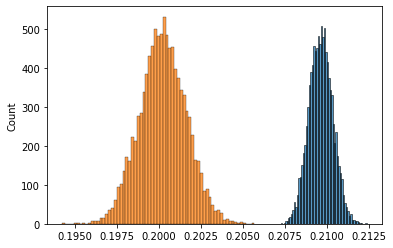

In [13]:
# визуализация глобальных значний ctr в каждой группе
sns.histplot(ctr1)
sns.histplot(ctr2)

<Axes: ylabel='Count'>

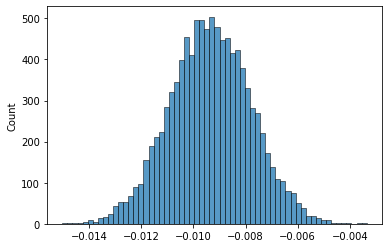

In [14]:
# разница между глобальными ctr
sns.histplot(ctr2 - ctr1)

In [15]:
# разница между глобальными ctr
ctr_diff = ctr2 - ctr1

# 95% доверительный интервал
ci = np.percentile(ctr_diff, [2.5, 97.5])

print(f'средняя разница ctr: {np.mean(ctr_diff):.6f}')
print(f'95% доверительный интервал: {ci}')

средняя разница ctr: -0.009358
95% доверительный интервал: [-0.01242366 -0.00629079]


In [16]:
# по результатам пуассоновского бутстрепа обнаружено статистически значимое снижение глобального CTR экспериментальной группы относительно контрольной.
# глобальный CTR контрольной группы составляет 0.2096, экспериментальной — 0.20027, средняя разница CTR составляет −0.009349
# 95% доверительный интервал разницы CTR составляет [-0.01235; -0.00623] и не включает ноль. это означает, что данные свидетельствуют о снижении глобального 
# CTR экспериментальной группы примерно на 0.62–1.24 процентного пункта
# таким образом, новый алгоритм рекомендаций статистически значимо снижает глобальный CTR

<Axes: xlabel='smothed_ctr', ylabel='Count'>

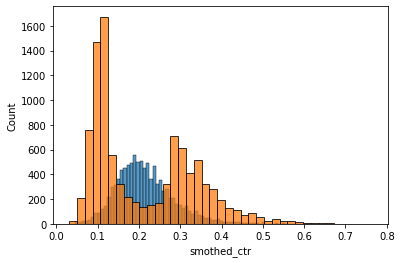

In [17]:
# функция для сглаживания ctr
def get_smothed_ctr(df, global_ctr, alpha):
    smothed_ctr = (df.likes + alpha * global_ctr) / (df.views + alpha)
    return smothed_ctr

# глобальные ctr в 1 и 2 группах
global_ctr1 = df[df.exp_group == 1].likes.sum() / df[df.exp_group == 1].views.sum()
global_ctr2 = df[df.exp_group == 2].likes.sum() / df[df.exp_group == 2].views.sum()

# делаем копии данных по 1 и 2 группам
group1 = df[df.exp_group == 1].copy()
group2 = df[df.exp_group == 2].copy()

# распределение сглаженного ctr в первой группе
group1['smothed_ctr'] = group1.apply(lambda x: get_smothed_ctr(x, global_ctr1, 5), axis=1)
sns.histplot(group1.smothed_ctr)

# распределение сглаженного ctr во второй группе
group2['smothed_ctr'] = group2.apply(lambda x: get_smothed_ctr(x, global_ctr2, 5), axis=1)
sns.histplot(group2.smothed_ctr)

In [18]:
# t-test на сглаженном ctr
p_value_ttest_smothed_ctr = stats.ttest_ind(group2.smothed_ctr,
                                            group1.smothed_ctr,
                                            equal_var=False).pvalue
print(f'p-value по t-test на сглаженном сtr: {p_value_ttest_smothed_ctr}')

p-value по t-test на сглаженном сtr: 0.05166679015318526


In [19]:
# после применения сглаживания Лапласа средние значения CTR в обеих группах снизились, при этом снижение оказалось более выраженным в экспериментальной группе
# по результатам t-test Уэлча на сглаженном CTR получено p-value = 0.0517, что немного превышает уровень статистической значимости 0.05, следовательно, 
# статистически значимых различий между средними сглаженными CTR групп не обнаружено
# таким образом, данный метод не позволяет подтвердить статистически значимое различие между группами на уровне значимости 5%

In [20]:
# функция хэширования
def group_split(id, n_groups):
    test_id = str(id)
    test_id_digest = hashlib.md5(test_id.encode('ascii')).hexdigest()
    test_id_final_int = int(test_id_digest, 16)
    return test_id_final_int % n_groups

In [21]:
# бакетное преобразование
users_buckets = df.copy()

# разделение пользователей на бакеты
users_buckets['bucket'] = users_buckets.swifter.apply(lambda x: group_split(x.user_id, 50), axis=1)

bucket_agg = users_buckets.groupby(['exp_group', 'bucket'], as_index=False).agg(
    likes=('likes', 'sum'), 
    views=('views', 'sum'),
    ctr9=('ctr', lambda x: x.quantile(0.9)))

# добавление столбца со средним значением ctr по бакетам
bucket_agg['bucket_ctr'] = bucket_agg.likes / bucket_agg.views

mean_ctr1 = bucket_agg[bucket_agg.exp_group == 1].bucket_ctr.mean()
mean_ctr2 = bucket_agg[bucket_agg.exp_group == 2].bucket_ctr.mean()

print(f'средние бакетные ctr в каждой группе:\nКонтрольная группа: {mean_ctr1:.5f} \nЭкспериментальная группа: {mean_ctr2:.5f}')

Pandas Apply:   0%|          | 0/19897 [00:00<?, ?it/s]

средние бакетные ctr в каждой группе:
Контрольная группа: 0.20964 
Экспериментальная группа: 0.20047


<Axes: xlabel='bucket_ctr', ylabel='Count'>

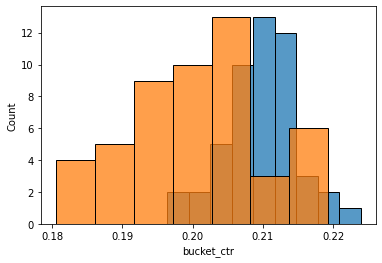

In [22]:
# распределение бакетного ctr в первой и второй группах
sns.histplot(bucket_agg[bucket_agg.exp_group == 1].bucket_ctr)
sns.histplot(bucket_agg[bucket_agg.exp_group == 2].bucket_ctr)

<Axes: xlabel='ctr9', ylabel='Count'>

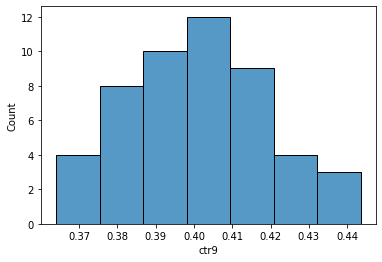

In [23]:
sns.histplot(bucket_agg[bucket_agg.exp_group == 2].ctr9)

In [24]:
# t-test поверх бакетного преобразования
p_value_ttest_bucket = stats.ttest_ind(bucket_agg[bucket_agg.exp_group == 2].bucket_ctr, 
                                       bucket_agg[bucket_agg.exp_group == 1].bucket_ctr,
                                       equal_var=False).pvalue
    
print(f'p-value по t-test после бакетного преобразования: {p_value_ttest_bucket}')

p-value по t-test после бакетного преобразования: 8.820387019679543e-08


In [25]:
# по результатам t-test Уэлча после бакетного преобразования получено p-value, значительно меньшее уровня статистической значимости 0.05, следовательно, 
# нулевая гипотеза отвергается
# обнаружены статистически значимые различия между средними бакетными CTR контрольной и экспериментальной групп, средний бакетный CTR экспериментальной 
# группы составляет 0.20047 против 0.20964 в контрольной группе
# таким образом, результаты бакетного анализа свидетельствуют о снижении CTR экспериментальной группы

In [26]:
# тест Манна-Уитни после бакетного преобразования
p_value_mannwhitneyu_bucket = stats.mannwhitneyu(bucket_agg[bucket_agg.exp_group == 2].bucket_ctr, 
                                                 bucket_agg[bucket_agg.exp_group == 1].bucket_ctr,
                                                 alternative = 'two-sided').pvalue

print(f'p-value по тесту Манна-Уитни после бакетного преобразования: {p_value_mannwhitneyu_bucket}')

p-value по тесту Манна-Уитни после бакетного преобразования: 4.755208744382036e-07


In [27]:
# По результатам теста Манна—Уитни после бакетного преобразования получено p-value, значительно меньшее уровня статистической значимости 0.05, следовательно, 
# нулевая гипотеза об отсутствии различий в распределениях бакетных CTR отвергается
# таким образом, результат согласуется с t-test после бакетного преобразования

## Общий вывод по результатам A/B-тестирования

В рамках эксперимента проверялась гипотеза о том, что новый алгоритм рекомендаций (экспериментальная группа 2) позволит увеличить CTR относительно контрольной группы 1.

В ходе анализа были применены несколько статистических методов, результаты которых показали неоднозначную картину.

**1. Средний пользовательский CTR.** По результатам t-test статистически значимых различий между средними пользовательскими CTR не обнаружено (p-value = 0.6854). При этом тест Манна—Уитни выявил значимые различия в распределениях CTR (p-value = 4.63e-45), что согласуется с более высокой неоднородностью экспериментальной группы.

**2. Глобальный CTR.** Пуассоновский бутстрэп показал статистически значимое снижение глобального CTR экспериментальной группы. Относительное снижение составило ~4.5%, а 95% доверительный интервал разницы CTR полностью находится ниже нуля.

**3. Сглаженный CTR.** После применения сглаживания Лапласа статистически значимых различий между группами не обнаружено (p-value = 0.0517). При этом средний сглаженный CTR экспериментальной группы оказался ниже контрольной.

**4. Бакетное преобразование.** Оба применённых теста — t-test и Манна—Уитни — выявили статистически значимые различия между группами. Средний бакетный CTR экспериментальной группы оказался ниже контрольной (0.20047 против 0.20964).

**Возможное объяснение результатов.**
Новый алгоритм мог изменить распределение показов между пользователями с разным уровнем CTR. Например, часть пользователей могла получать больше релевантных рекомендаций, а другая часть — меньше. Это привело бы к увеличению неоднородности экспериментальной группы, при этом пользователи с низким CTR могли генерировать больше просмотров, что объясняет снижение глобального CTR при практически неизменном среднем пользовательском CTR.
Таким образом, несмотря на отсутствие статистически значимых различий между средними индивидуальными CTR, анализ глобального и бакетного CTR указывает на снижение эффективности нового алгоритма рекомендаций.

**Рекомендация:** не рекомендую полный запуск нового алгоритма на основании результатов данного эксперимента. Пуассоновский бутстрэп и бакетное преобразование показывают снижение CTR экспериментальной группы, а статистически значимого улучшения основной метрики не обнаружено.